In [39]:
import numpy as np
import math as math

In [40]:
m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle), -math.sin(angle)], [math.sin(angle),
math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
n = 100
points = np.random.multivariate_normal(m,s,n)

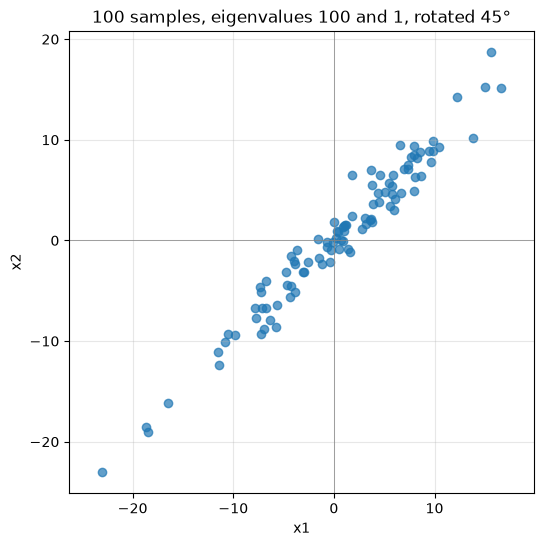

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(points[:, 0], points[:, 1], alpha=0.7)
plt.axhline(0, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("100 samples, eigenvalues 100 and 1, rotated 45°")
plt.grid(alpha=0.3)
plt.show()


In [42]:
print(points)
    

[[ 3.13861670e+00  2.22663506e+00]
 [ 4.59139905e+00  6.52725870e+00]
 [-7.26419231e+00 -5.10548191e+00]
 [-4.73735499e+00 -3.16235417e+00]
 [ 1.49784214e+01  1.52219125e+01]
 [ 6.94561572e+00  7.14438885e+00]
 [-7.10078384e+00 -6.68639582e+00]
 [-2.30056210e+01 -2.30056067e+01]
 [-2.55391873e+00 -2.13827922e+00]
 [ 7.34614454e+00  7.10932689e+00]
 [-6.91143704e+00 -8.80344619e+00]
 [-3.87170027e+00 -2.34331018e+00]
 [ 7.91647814e+00  4.93098696e+00]
 [-7.19048858e-01 -6.25095134e-01]
 [ 8.21183223e+00  8.21338786e+00]
 [ 4.93494036e-01 -8.22659205e-01]
 [-2.94539434e+00 -3.13093128e+00]
 [ 2.25794228e-01  2.12866617e-01]
 [ 9.81850762e+00  9.85348225e+00]
 [ 3.83079591e+00  1.84213245e+00]
 [-4.63568896e+00 -4.38879869e+00]
 [-4.31723203e+00 -5.67137125e+00]
 [ 1.58654876e+00 -1.16863725e+00]
 [-1.52316596e+00 -1.76161822e+00]
 [ 4.10641897e-01  8.11729316e-01]
 [ 5.62611193e+00  3.46253736e+00]
 [ 5.03017479e-02  1.84770812e+00]
 [-7.81018167e+00 -6.75833088e+00]
 [-2.68598206e-01 -9

In [43]:
points[99]= [99, -35]

def diff(points): 
    return (points[:,0] - points[:,1])
diff(points)

array([ 9.11981638e-01, -1.93585965e+00, -2.15871040e+00, -1.57500083e+00,
       -2.43491116e-01, -1.98773134e-01, -4.14388019e-01, -1.43595315e-05,
       -4.15639507e-01,  2.36817655e-01,  1.89200916e+00, -1.52839009e+00,
        2.98549118e+00, -9.39537239e-02, -1.55562459e-03,  1.31615324e+00,
        1.85536943e-01,  1.29276116e-02, -3.49746367e-02,  1.98866346e+00,
       -2.46890270e-01,  1.35413922e+00,  2.75518601e+00,  2.38452259e-01,
       -4.01087419e-01,  2.16357456e+00, -1.79740637e+00, -1.05185079e+00,
        7.25169735e-01,  1.44520322e+00,  5.59334047e-01,  4.61549968e-02,
        2.25918787e+00, -1.39883345e+00,  2.05128764e+00, -3.06170079e-01,
       -1.73581935e+00,  1.73629089e+00,  5.59666707e-01,  3.27654856e-01,
        1.87719084e+00,  2.61400524e-01, -5.82477979e-01,  3.66148483e+00,
       -6.74207836e-01,  1.26181560e+00, -4.52691003e-01,  2.27496552e+00,
       -3.31137541e-01, -3.14247318e-01,  1.10885912e-01,  2.86947087e+00,
       -7.36058976e-01, -

In [44]:
def lsm(array):
    return (1/2)*np.sum(array**2)

lsm(diff(points))

np.float64(9098.92388166525)

In [45]:
def loss_cacuchy(array, c=1):
    return (c**2/2)*np.sum(np.log(1 + (array/c)**2))

loss_cacuchy(diff(points))

np.float64(47.955808208506824)

# Third Practice

### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336

## 1. Introduction task

We define a set of samples form a lineal model with high noise.

In [46]:
m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle), -math.sin(angle)], [math.sin(angle), math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
n = 100
points = np.random.multivariate_normal(m,s,n)

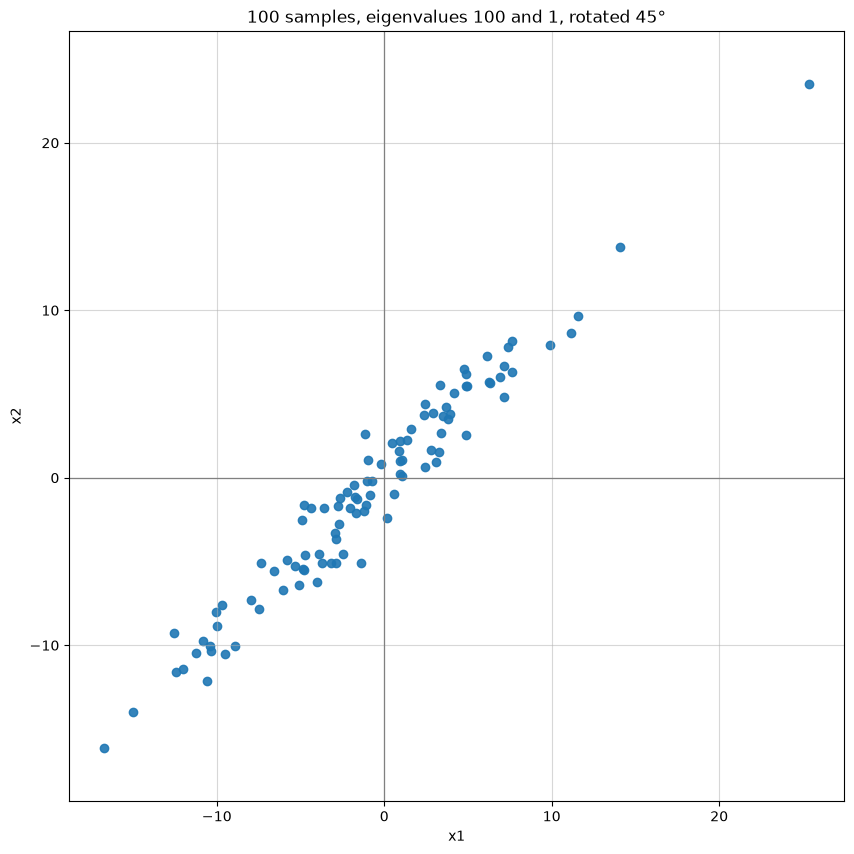

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
plt.scatter(points[:, 0], points[:, 1], alpha=0.9)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"{n} samples, eigenvalues {lamb[0,0]} and {lamb[1,1]}, rotated {int(angle*180/math.pi)}°")
plt.grid(alpha=0.5)
plt.show()


We will now try to find the linear model that fits best the set of points we defined.

Our model will be $w_{1}x + w_{0}$. The goal is to find the parameters $w_{1}$ and $w_{0}$ that minmize a function that might as well be the `Least Squares` function and then use any type of _descent method_ that helps us minimize the function.

#### Loss function model

The loss function model, applied to our case, consists in minimizing $Q$ given a set of points $\{(x_{i},y_{i})\}_{i=1}^{m}$, where $Q$ is the defined as:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(\hat{y}_{i}-y_{i})^{2}
$$

With $\hat{y}_{i} = f(x_{i})$, the value we expect from our model.

In other words, we want to minimize:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(w_{1}x_{i} + w_{0} - y_{i})^{2}
$$

To do so, we will use the tools from sessions 1 and 2. We consider $Q(w) = Q(w_{0}, w_{1})$ the function to minimize.

As we have done repeatedly in the past, we will calculate the gradient, skipping the calculations for the sake of simplicity and _cleanness_.

$$
\nabla Q =
\begin{pmatrix}
\dfrac{\partial Q}{\partial w_0} \\[2ex]
\dfrac{\partial Q}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i) \\[2ex]
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i)\,x_i
\end{pmatrix}
$$


### 1.1 Implement the Least Squares method

We will use backtracking to minimze $Q(w)$. We will be reusing the code from Session 2.

In [48]:
def LSM(array, w0, w1):
    return (1/2)*np.sum((w1 * array[:, 0] + w0 - array[:, 1])**2)

def LSM_grad(array, w0, w1):
    res = w1 * array[:, 0] + w0 - array[:, 1]
    grad_w0 = np.sum(res)
    grad_w1 = np.sum(res * array[:, 0])
    return np.array([grad_w0, grad_w1])

def grad_desc_backtracking(f, grad_f, x0, x1, alpha0=1, tol=1e-5, max_iter=10000, alpha_min=1e-5, reset=False):
    x = np.array([x0, x1])
    path = [x]
    alphas = []
    n_halvings = 0
    alpha = alpha0
    for k in range(max_iter):
        grad = grad_f(x)
        if np.linalg.norm(grad) < tol:
            break
        if reset:
            alpha = alpha0
        while f(x - alpha * grad) >= f(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        x = x - alpha * grad
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

[0.02338043 0.93526866] 592 17


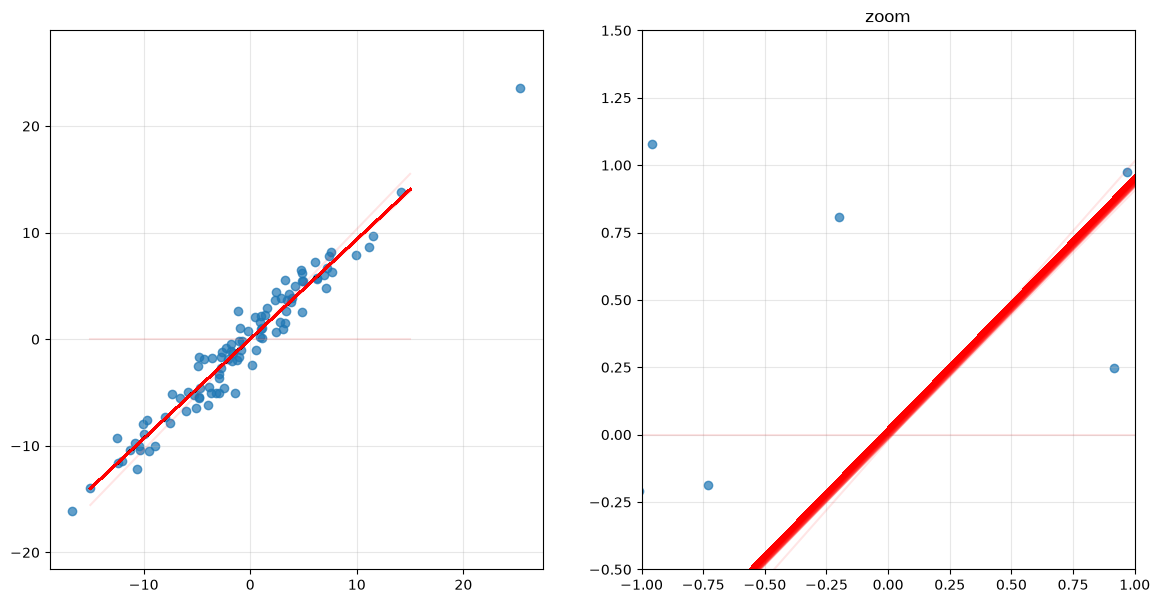

In [49]:
def f(w):
    return LSM(points, w[0], w[1])

def grad_f(w):
    return LSM_grad(points, w[0], w[1])

path, alphas, n_halvings = grad_desc_backtracking(f, grad_f, 0, 0)
print(path[-1], len(path), n_halvings)

x = np.linspace(-15, 15, 100)

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
for ax in axs:
    ax.scatter(points[:, 0], points[:, 1], alpha=0.7)
    for k in range(len(path)):
        w0, w1 = path[k]
        ax.plot(x, w1 * x + w0, color="red", alpha=0.1 + 0.9 * k / (len(path) - 1))
    ax.grid(alpha=0.3)

axs[0].axis("equal")
axs[1].set_xlim(-1, 1)
axs[1].set_ylim(-0.5, 1.5)
axs[1].set_title("zoom")
plt.show()